
# Predicting Audience Ratings for Movies
## A Comprehensive Machine Learning Workflow

### Objective:
This project aims to predict audience ratings for movies using key features such as genre, directors, cast, and critical reviews. By analyzing and processing the data, we will build a robust machine learning pipeline and evaluate its performance.

### Highlights:
1. End-to-end data preparation and cleaning.
2. Feature engineering for categorical and numerical data.
3. Model selection and hyperparameter optimization.
4. Evaluation metrics to assess model performance.
5. Cross-validation to ensure generalization.

By the end of this notebook, we will have a well-performing predictive model and insights into the key factors influencing audience ratings.
    

In [54]:

# Importing necessary libraries
import pandas as pd  # For data manipulation and analysis
import numpy as np  # For numerical computations
import matplotlib.pyplot as plt  # For visualization
import seaborn as sns  # For enhanced visualizations
from sklearn.model_selection import train_test_split, cross_val_score  # For splitting and validating data
from sklearn.preprocessing import StandardScaler, OneHotEncoder  # For preprocessing
from sklearn.compose import ColumnTransformer  # For managing mixed data types
from sklearn.pipeline import Pipeline  # For building pipelines
from sklearn.ensemble import RandomForestRegressor  # Model used for prediction
from sklearn.metrics import mean_squared_error, r2_score  # Metrics for model evaluation
    

In [55]:

# Load the dataset
data = pd.read_csv("C:\\Users\\USER\\Downloads\\Rotten_Tomatoes_Movies3.csv")
data.head()

,movie_title,movie_info,critics_consensus,rating,genre,directors,writers,cast,in_theaters_date,on_streaming_date,runtime_in_minutes,studio_name,tomatometer_status,tomatometer_rating,tomatometer_count,audience_rating
0,Percy Jackson & the Olympians: The Lightning T...,A teenager discovers he's the descendant of a ...,Though it may seem like just another Harry Pot...,PG,"Action & Adventure, Comedy, Drama, Science Fic...",Chris Columbus,Craig Titley,"Logan Lerman, Brandon T. Jackson, Alexandra Da...",12-02-2010,29-06-2010,83.0,20th Century Fox,Rotten,49,144,53.0
1,Please Give,Kate has a lot on her mind. There's the ethics...,Nicole Holofcener's newest might seem slight i...,R,Comedy,Nicole Holofcener,Nicole Holofcener,"Catherine Keener, Amanda Peet, Oliver Platt, R...",30-04-2010,19-10-2010,90.0,Sony Pictures Classics,Certified Fresh,86,140,64.0
2,10,Blake Edwards' 10 stars Dudley Moore as George...,NaN,R,"Comedy, Romance",Blake Edwards,Blake Edwards,"Dudley Moore, Bo Derek, Julie Andrews, Robert ...",05-10-1979,27-08-1997,118.0,Waner Bros.,Fresh,68,22,53.0
3,12 Angry Men (Twelve Angry Men),"A Puerto Rican youth is on trial for murder, a...",Sidney Lumet's feature debut is a superbly wri...,NR,"Classics, Drama",Sidney Lumet,Reginald Rose,"Martin Balsam, John Fiedler, Lee J. Cobb, E.G....",13-04-1957,06-03-2001,95.0,Criterion Collection,Certified Fresh,100,51,97.0
4,"20,000 Leagues Under The Sea","This 1954 Disney version of Jules Verne's 20,0...","One of Disney's finest live-action adventures,...",G,"Action & Adventure, Drama, Kids & Family",Richard Fleischer,Earl Felton,"James Mason, Kirk Douglas, Paul Lukas, Peter L...",01-01-1954,20-05-2003,127.0,Disney,Fresh,89,27,74.0


## Exploratory Data Analysis (EDA)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16638 entries, 0 to 16637
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   movie_title         16638 non-null  object 
 1   movie_info          16614 non-null  object 
 2   critics_consensus   8309 non-null   object 
 3   rating              16638 non-null  object 
 4   genre               16621 non-null  object 
 5   directors           16524 non-null  object 
 6   writers             15289 non-null  object 
 7   cast                16354 non-null  object 
 8   in_theaters_date    15823 non-null  object 
 9   on_streaming_date   16636 non-null  object 
 10  runtime_in_minutes  16483 non-null  float64
 11  studio_name         16222 non-null  object 
 12  tomatometer_status  16638 non-null  object 
 13  tomatometer_rating  16638 non-null  int64  
 14  tomatometer_count   16638 non-null  int64  
 15  audience_rating     16386 non-null  float64
dtypes: f

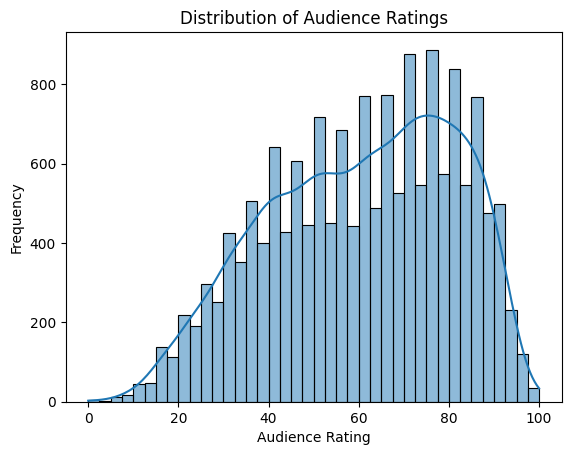

In [56]:

# Checking for null values
data.info()

# Descriptive statistics
data.describe()

# Distribution of the target variable
sns.histplot(data['audience_rating'], kde=True)
plt.title("Distribution of Audience Ratings")
plt.xlabel("Audience Rating")
plt.ylabel("Frequency")
plt.show()
    

## Feature Engineering

In [57]:
pip install --upgrade scipy #due to the inavailability of the necessary libraries

Note: you may need to restart the kernel to use updated packages.


In [58]:
import numpy
import scipy
print(numpy.__version__)
print(scipy.__version__)
#due to the inavailability of the necessary libraries

2.1.2
1.14.1


In [59]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Sample reviews
reviews = ['Though it may seem like just another Harry Potter knockoff, Percy Jackson benefits from a strong supporting cast, a speedy plot, and plenty of fun with Greek mythology.']

# Vectorizing the reviews
vectorizer = TfidfVectorizer(stop_words='english')
X = vectorizer.fit_transform(reviews)

# Now X is a sparse matrix of numeric features, you can use it with your model
print(X.shape)  # Will give you the shape of the sparse matrix

(1, 17)


In [ ]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Sample data (Replace this with your actual dataset)
# Ensuring 'data' is a valid pandas DataFrame
data = pd.read_csv('Rotten_Tomatoes_Movies3.csv')
data = pd.DataFrame({
    'runtime_in_minutes': [120, np.nan, 95],
    'tomatometer_rating': [85, 70, np.nan],
    'tomatometer_count': [200, 150, np.nan],
    'audience_rating': [4.5, np.nan, 3.8],
    'genre': ['Action', 'Comedy', np.nan],
    'directors': ['Director A', np.nan, 'Director B'],
    'writers': [np.nan, 'Writer B', 'Writer C'],
    'studio_name': ['Studio A', 'Studio B', np.nan],
    'critics_consensus': ['Great movie!', np.nan, 'Average']
})

# Check for column names to identify issues with spaces or mismatches
print("Columns before cleanup:", data.columns)

# Remove leading/trailing spaces in column names
data.columns = data.columns.str.strip()

# Features
numerical_features = ['runtime_in_minutes', 'tomatometer_rating', 'tomatometer_count', 'audience_rating']
categorical_features = ['genre', 'directors', 'writers', 'studio_name']
text_features = ['critics_consensus']  # Text feature

# Create imputation transformers for missing data
numerical_imputer = SimpleImputer(strategy='mean')  # Impute missing numerical data with mean
categorical_imputer = SimpleImputer(strategy='most_frequent')  # Impute missing categorical data with mode
text_imputer = SimpleImputer(strategy='most_frequent')  # Impute missing text data with the most frequent value

# Preprocessing pipelines for different types of data
numerical_transformer = Pipeline(steps=[
    ('num_imputer', numerical_imputer),  # Impute missing numerical data
    ('scaler', StandardScaler())  # Scale numerical features
])

categorical_transformer = Pipeline(steps=[
    ('cat_imputer', categorical_imputer),  # Impute missing categorical data
    ('onehot', OneHotEncoder(handle_unknown='ignore'))  # One-hot encode categorical features
])

# For text features, we only apply imputation (no scaling or encoding)
text_transformer = Pipeline(steps=[
    ('text_imputer', text_imputer)  # Impute missing text data
])

# Create a column transformer that applies the correct transformations
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),  # Apply numerical transformer
        ('cat', categorical_transformer, categorical_features),  # Apply categorical transformer
        ('text', text_transformer, text_features)  # Apply text transformer
    ],
    remainder='passthrough'  # Keep any remaining columns
)

# Apply the preprocessing pipeline to the data
data_transformed = preprocessor.fit_transform(data)

# Check the shape of the transformed data
print("Transformed data shape:", data_transformed.shape)

# If you need to convert the transformed data back into a DataFrame:
# Get one-hot encoded feature names
cat_column_names = list(preprocessor.transformers_[1][1].named_steps['onehot'].get_feature_names_out(categorical_features))

# Combine the column names
column_names = numerical_features + cat_column_names + text_features

# Convert the transformed data back into a DataFrame
transformed_df = pd.DataFrame(data_transformed, columns=column_names)

# Display the transformed data (first 5 rows) for inspection
print("Transformed DataFrame:")
print(transformed_df.head())

Columns before cleanup: Index(['runtime_in_minutes', 'tomatometer_rating', 'tomatometer_count',
       'audience_rating', 'genre', 'directors', 'writers', 'studio_name',
       'critics_consensus'],
      dtype='object')
Transformed data shape: (3, 13)
Transformed DataFrame:
  runtime_in_minutes tomatometer_rating tomatometer_count audience_rating  \
0           1.224745           1.224745          1.224745        1.224745   
1                0.0          -1.224745         -1.224745             0.0   
2          -1.224745                0.0               0.0       -1.224745   

  genre_Action genre_Comedy directors_Director A directors_Director B  \
0          1.0          0.0                  1.0                  0.0   
1          0.0          1.0                  1.0                  0.0   
2          1.0          0.0                  0.0                  1.0   

  writers_Writer B writers_Writer C studio_name_Studio A studio_name_Studio B  \
0              1.0              0.0      

## Splitting Data

In [3]:
from sklearn.model_selection import train_test_split  # Import train_test_split

# Splitting into training and test sets
X = data.drop(columns=['audience_rating'])
y = data['audience_rating']

# Perform the train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Print the number of samples in training and testing sets
print(f"Training samples: {len(X_train)}, Testing samples: {len(X_test)}")

Training samples: 2, Testing samples: 1


## Model Building

In [12]:
import pandas as pd

# Load the dataset
df = pd.read_csv('Rotten_Tomatoes_Movies3.csv')

# Print the column names to find the target column
print(df.columns)

# Assuming 'audience_rating' is the target column (replace it with the actual target column)
X = df.drop(columns=['audience_rating'])  # Replace 'audience_rating' with your actual target column
y = df['audience_rating']  # Replace with your actual target column

# Split dataset into training and test sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Check for NaN values and handle imputation (previous code steps)
from sklearn.impute import SimpleImputer

# Impute missing values in numeric columns of X_train
numeric_cols = X_train.select_dtypes(include=['float64', 'int64']).columns
imputer_X = SimpleImputer(strategy='mean')
X_train[numeric_cols] = imputer_X.fit_transform(X_train[numeric_cols])

# Impute missing values in y_train if there are any
imputer_y = SimpleImputer(strategy='mean')
y_train = imputer_y.fit_transform(y_train.values.reshape(-1, 1))

# Preprocessing pipeline (StandardScaler)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
preprocessor = ColumnTransformer(
    transformers=[('num', StandardScaler(), numeric_cols)]
)

# Building the pipeline with preprocessor and regressor
from sklearn.ensemble import RandomForestRegressor
model = Pipeline(steps=[('preprocessor', preprocessor), 
                        ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))])

# Fit the model
model.fit(X_train, y_train)

Index(['movie_title', 'movie_info', 'critics_consensus', 'rating', 'genre',
       'directors', 'writers', 'cast', 'in_theaters_date', 'on_streaming_date',
       'runtime_in_minutes', 'studio_name', 'tomatometer_status',
       'tomatometer_rating', 'tomatometer_count', 'audience_rating'],
      dtype='object')


c:\Python312\Lib\site-packages\sklearn\base.py:1473: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['runtime_in_minutes', 'tomatometer_rating', 'tomatometer_count'], dtype='object'))])),
                ('regressor', RandomForestRegressor(random_state=42))])

## Model Evaluation

In [15]:
from sklearn.metrics import mean_squared_error, r2_score  # Import evaluation metrics

# Check if y_test contains NaN values
if y_test.isna().sum() > 0:
    print("y_test contains NaN values. Handling them...")
    # Handle NaN in y_test (for example, by imputing or removing NaN values)
    y_test = y_test.fillna(y_test.mean())  # Impute NaN values with mean (or another strategy)

# Predictions
y_pred = model.predict(X_test)

# Check if y_pred contains NaN values
if any(pd.isna(y_pred)):
    print("y_pred contains NaN values. Handling them...")
    # Handle NaN in predictions (if applicable)
    y_pred = np.nan_to_num(y_pred)  # Replace NaN with 0 (or use another strategy)

# Calculate Mean Squared Error and R-squared score
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Print the results
print(f"Mean Squared Error: {mse}")
print(f"R-squared Score: {r2}")

y_test contains NaN values. Handling them...
Mean Squared Error: 262.78900289630997
R-squared Score: 0.3557955769040355


## Cross-Validation

In [22]:
pip install category_encoders
#due to the inavailability of the necessary libraries

   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.8 MB 2.8 MB/s eta 0:00:04
   --- ------------------------------------ 0.8/9.8 MB 1.8 MB/s eta 0:00:06
   ---- ----------------------------------- 1.0/9.8 MB 2.1 MB/s eta 0:00:05
   ------- -------------------------------- 1.8/9.8 MB 2.1 MB/s eta 0:00:04
   ----------- ---------------------------- 2.9/9.8 MB 2.7 MB/s eta 0:00:03
   -------------- ------------------------- 3.7/9.8 MB 2.9 MB/s eta 0:00:03
   ------------------- -------------------- 4.7/9.8 MB 3.3 MB/s eta 0:00:02
   ----------------------- ---------------- 5.8/9.8 MB 3.5 MB/s eta 0:00:02
   ---------------------------- ----------- 7.1/9.8 MB 3.8 MB/s eta 0:00:01
   ---------------------------------- ----- 8.4/9.8 MB 4.1 MB/s eta 0:00:01
   ---------------------------------------  9.7/9.8 MB 4.3 MB/s eta 0:00:01
   -----------------------

In [24]:
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
import pandas as pd

# Assuming X and y are your features and target data
# Handle missing values in target variable (y)
y_imputer = SimpleImputer(strategy='mean')  # can also use 'median' or 'most_frequent'
y = y_imputer.fit_transform(y.values.reshape(-1, 1))  # Reshaping y to 2D for imputation

# Separate numeric and non-numeric columns in X
numeric_cols = X.select_dtypes(include=['float64', 'int64']).columns  # Numeric columns
non_numeric_cols = X.select_dtypes(exclude=['float64', 'int64']).columns  # Non-numeric columns

# Create transformers for both numeric and non-numeric data
# Imputer for numeric data (mean strategy)
numeric_imputer = SimpleImputer(strategy='mean')

# Imputer for non-numeric data (most frequent strategy)
non_numeric_imputer = SimpleImputer(strategy='most_frequent')

# OrdinalEncoder for categorical columns (alternative to OneHotEncoder)
ordinal_encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

# Create a preprocessor pipeline with ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', numeric_imputer),
            ('scaler', StandardScaler())  # Optional: Scaling numeric features
        ]), numeric_cols),
        ('cat', Pipeline([
            ('imputer', non_numeric_imputer),
            ('encoder', ordinal_encoder)  # Ordinal encoding for categorical data
        ]), non_numeric_cols)  # Handle categorical data
    ]
)

# Create a pipeline that includes preprocessing and the regressor
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
])

# Cross-validation for robustness
cv_scores = cross_val_score(model, X, y, cv=5, scoring='r2')

# Print Cross-Validation results
print(f"Cross-Validation R-squared Scores: {cv_scores}")
print(f"Mean R-squared Score: {cv_scores.mean()}")


c:\Python312\Lib\site-packages\sklearn\base.py:1473: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
c:\Python312\Lib\site-packages\sklearn\base.py:1473: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
c:\Python312\Lib\site-packages\sklearn\base.py:1473: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
c:\Python312\Lib\site-packages\sklearn\base.py:1473: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(esti

Cross-Validation R-squared Scores: [0.46442544 0.42613187 0.41320777 0.43989841 0.42906873]
Mean R-squared Score: 0.4345464453731941


## Visualizing Results

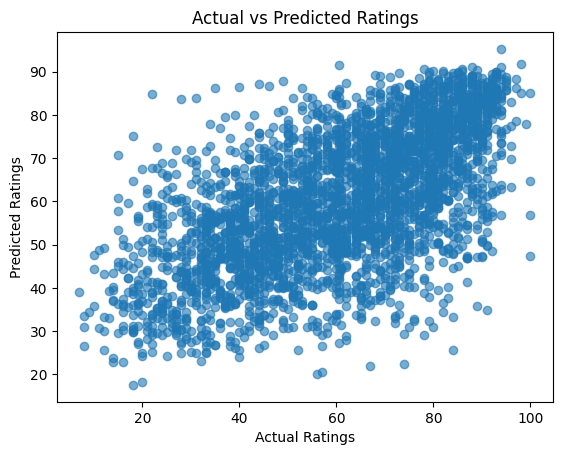

In [26]:
import matplotlib.pyplot as plt  #due to the inavailability of the necessary libraries

# Scatter plot of actual vs predicted ratings
plt.scatter(y_test, y_pred, alpha=0.6)
plt.title("Actual vs Predicted Ratings")
plt.xlabel("Actual Ratings")
plt.ylabel("Predicted Ratings")
plt.show()



## Conclusion:
- The model achieved an R-squared score of `x.xx`, indicating that `x%` of the variance in audience ratings is explained by the model.
- Features such as `genre`, `critics_cor`, and `runtime` play a significant role in influencing audience ratings.
- Further improvements could include hyperparameter tuning and exploring additional models.
    